# Decision Tree Induction: Worked Example (Play Golf)

This notebook goes with the Week 6 lecture *Classification Problems and Decision Tree Induction*. It recomputes the lecture's worked example step by step in Python, so you can check every number on the slides and then change the data yourself.

**The problem.** We have 14 days of weather data (Outlook, Temp, Humidity, Windy) and, for each day, whether golf was played (the class label `Play`). We want a decision tree that predicts `Play` from the weather.

**How to run it.** Run the cells from top to bottom (**Run → Run All Cells**, or press **Shift + Enter** on each cell). Everything runs in your browser on the course website; there is nothing to install.

**What you should get:** the values of the lecture slides. The notebook prints 4 decimal places; the slides round intermediate results to 3, so their last digit can differ by 1 (for example the gain ratio of Outlook is 0.1564 here and 0.247 / 1.577 = 0.157 on slide 29).

| Quantity | Slide | Value |
|---|---|---|
| Entropy of the target, E(Play) | 18 | 0.940 |
| Entropy after splitting on Outlook, E(Play, Outlook) | 19 | 0.693 |
| Information gain of Outlook, Temp, Humidity, Windy | 21 | 0.247, 0.029, 0.152, 0.048 |
| Gain ratio of Outlook | 29–30 | 0.157 |
| Gini(D), Gini after the Rainy / not Rainy split, reduction in impurity | 33 | 0.4592, 0.3937, 0.0655 |

and the tree and rules R1–R5 of slide 25.

## 1. The data

The table below is the Play Golf data from slides 12 and 33. Each row is one day. We type it in directly, so the notebook needs no data file.

In [1]:
import numpy as np
import pandas as pd

# The 14 days of the Play Golf example (slides 12 and 33)
df = pd.DataFrame({
    "Outlook":  ["Rainy", "Rainy", "Overcast", "Sunny", "Sunny", "Sunny", "Overcast",
                 "Rainy", "Rainy", "Sunny", "Rainy", "Overcast", "Overcast", "Sunny"],
    "Temp":     ["Hot", "Hot", "Hot", "Mild", "Cool", "Cool", "Cool",
                 "Mild", "Cool", "Mild", "Mild", "Mild", "Hot", "Mild"],
    "Humidity": ["High", "High", "High", "High", "Normal", "Normal", "Normal",
                 "High", "Normal", "Normal", "Normal", "High", "Normal", "High"],
    "Windy":    [False, True, False, False, False, True, True,
                 False, False, False, True, True, False, True],
    "Play":     ["No", "No", "Yes", "Yes", "Yes", "No", "Yes",
                 "No", "Yes", "Yes", "Yes", "Yes", "Yes", "No"],
})
df

,Outlook,Temp,Humidity,Windy,Play
0,Rainy,Hot,High,False,No
1,Rainy,Hot,High,True,No
2,Overcast,Hot,High,False,Yes
3,Sunny,Mild,High,False,Yes
4,Sunny,Cool,Normal,False,Yes
5,Sunny,Cool,Normal,True,No
6,Overcast,Cool,Normal,True,Yes
7,Rainy,Mild,High,False,No
8,Rainy,Cool,Normal,False,Yes
9,Sunny,Mild,Normal,False,Yes


## 2. Entropy of the target (slide 18)

Entropy measures how mixed the class labels are: $E(S) = -\sum_i p_i \log_2 p_i$, where $p_i$ is the share of examples in class $i$. It is 0 when all examples have the same label and 1 for a 50/50 split of two classes. Here 9 days are *Yes* and 5 are *No*.

In [2]:
def entropy(labels):
    # Share of each class label, e.g. Yes: 9/14, No: 5/14
    p = labels.value_counts(normalize=True)
    # E(S) = -sum(p * log2 p)
    return float(-(p * np.log2(p)).sum())

print(df["Play"].value_counts().to_dict())
print(f"E(Play) = {entropy(df['Play']):.4f}")

{'Yes': 9, 'No': 5}
E(Play) = 0.9403


## 3. Entropy after a split (slide 19)

If we split the days by one attribute, each branch has its own entropy. The entropy of the split is the average of the branch entropies, weighted by the share of days in each branch: $E(T, X) = \sum_{c \in X} P(c)\,E(c)$.

In [3]:
def split_entropy(data, attribute, target="Play"):
    total = 0.0
    for value, branch in data.groupby(attribute):
        weight = len(branch) / len(data)             # P(c): share of days in this branch
        total += weight * entropy(branch[target])    # weighted entropy of the branch
    return total

# Yes/No counts per Outlook value (the frequency table on slide 19)
print(pd.crosstab(df["Outlook"], df["Play"]))
print()
print(f"E(Play, Outlook) = {split_entropy(df, 'Outlook'):.4f}")

Play      No  Yes
Outlook          
Overcast   0    4
Rainy      3    2
Sunny      2    3

E(Play, Outlook) = 0.6935


## 4. Information gain of every attribute (slides 20–21)

Information gain is the drop in entropy caused by a split: $Gain(T, X) = E(T) - E(T, X)$. ID3 puts the attribute with the **largest** gain at the root.

In [4]:
def information_gain(data, attribute, target="Play"):
    return entropy(data[target]) - split_entropy(data, attribute, target)

attributes = ["Outlook", "Temp", "Humidity", "Windy"]
gains = pd.Series({a: information_gain(df, a) for a in attributes}, name="Information gain")
gains.round(4)

Outlook     0.2467
Temp        0.0292
Humidity    0.1518
Windy       0.0481
Name: Information gain, dtype: float64

Outlook has the largest gain (0.2467, shown as 0.247 on the slide), so it becomes the root node, as on slide 21.

## 5. Gain ratio (slides 28–30)

Information gain favours attributes with many values. The gain ratio divides the gain by the *split entropy* (also called split information), the entropy of the branch sizes themselves: $GainRatio(S, A) = Gain(S, A) / SplitEntropy(S, A)$.

In [5]:
def split_info(data, attribute):
    # Entropy of the branch sizes, e.g. Outlook: 5, 4 and 5 days
    return entropy(data[attribute])

table = pd.DataFrame({
    "Gain": gains,
    "Split info": [split_info(df, a) for a in attributes],
})
table["Gain ratio"] = table["Gain"] / table["Split info"]
table.round(4)

,Gain,Split info,Gain ratio
Outlook,0.2467,1.5774,0.1564
Temp,0.0292,1.5567,0.0188
Humidity,0.1518,1.0000,0.1518
Windy,0.0481,0.9852,0.0488


These are the values in the table on slide 30, to rounding (for example Outlook: 0.2467 / 1.5774 = 0.1564; the slide divides the rounded values, 0.247 / 1.577 = 0.157).

## 6. Gini index (slides 32–33)

The Gini index is another impurity measure, $Gini(D) = 1 - \sum_i p_i^2$, which needs no logarithm. CART uses binary splits, so slide 33 splits the days into *Rainy* and *not Rainy*. The **reduction in impurity** is $\Delta Gini = Gini(D) - Gini_A(D)$.

In [6]:
def gini(labels):
    p = labels.value_counts(normalize=True)
    return float(1 - (p ** 2).sum())

rainy = df[df["Outlook"] == "Rainy"]        # D1: 5 days (2 Yes, 3 No)
not_rainy = df[df["Outlook"] != "Rainy"]    # D2: 9 days (7 Yes, 2 No)

gini_d = gini(df["Play"])
# Weighted Gini of the two branches: |D1|/|D| Gini(D1) + |D2|/|D| Gini(D2)
gini_rainy = len(rainy) / len(df) * gini(rainy["Play"]) + len(not_rainy) / len(df) * gini(not_rainy["Play"])

print("Gini(D)              =", round(gini_d, 4))
print("Gini_rainy(D)        =", round(gini_rainy, 4))
print("Reduction in impurity =", round(gini_d - gini_rainy, 4))

Gini(D)              = 0.4592
Gini_rainy(D)        = 0.3937
Reduction in impurity = 0.0655


## 7. Building the whole tree with ID3 (slides 21–25)

ID3 repeats the same step on every branch: pick the attribute with the largest information gain, split, and stop when a branch is pure (entropy 0, slide 23). The short recursive function below does exactly that and prints each path from the root to a leaf as an IF … THEN rule.

In [7]:
def id3(data, attributes, target="Play"):
    labels = data[target]
    # Stop: the branch is pure, or there is nothing left to split on -> leaf with the majority class
    if labels.nunique() == 1 or not attributes:
        return labels.mode()[0]
    # Choose the attribute with the largest information gain
    best = max(attributes, key=lambda a: information_gain(data, a, target))
    remaining = [a for a in attributes if a != best]
    return {best: {value: id3(branch, remaining, target)
                   for value, branch in data.groupby(best)}}

def print_rules(tree, conditions=()):
    if not isinstance(tree, dict):                      # a leaf: print the finished rule
        print("IF " + " AND ".join(conditions) + f" THEN Play={tree}")
        return
    (attribute, branches), = tree.items()
    for value, subtree in branches.items():
        print_rules(subtree, conditions + (f"({attribute}={value})",))

tree = id3(df, attributes)
print_rules(tree)

IF (Outlook=Overcast) THEN Play=Yes
IF (Outlook=Rainy) AND (Humidity=High) THEN Play=No
IF (Outlook=Rainy) AND (Humidity=Normal) THEN Play=Yes
IF (Outlook=Sunny) AND (Windy=False) THEN Play=Yes
IF (Outlook=Sunny) AND (Windy=True) THEN Play=No


These are the five rules R1–R5 of slide 25, in a different order: Overcast always means *Yes*; on Sunny days the decision depends on Windy, on Rainy days on Humidity. Temp is never used.

## 8. The same task with scikit-learn (slide 26)

In practice you use a library. scikit-learn's `DecisionTreeClassifier` with `criterion="entropy"` chooses splits by information gain, like ID3, but it always makes **binary** splits (it implements CART) and it needs numbers, so we first turn each category into a 0/1 column with `pd.get_dummies`.

In [8]:
from sklearn.tree import DecisionTreeClassifier, export_text

# One 0/1 column per category, e.g. Outlook_Sunny, Outlook_Rainy, ...
X = pd.get_dummies(df[["Outlook", "Temp", "Humidity", "Windy"]].astype(str)).astype(int)
y = df["Play"]

model = DecisionTreeClassifier(criterion="entropy", random_state=0)  # entropy = information gain
model.fit(X, y)
print(export_text(model, feature_names=list(X.columns)))
print("Training accuracy:", model.score(X, y))

|--- Outlook_Overcast <= 0.50
|   |--- Humidity_Normal <= 0.50
|   |   |--- Outlook_Rainy <= 0.50
|   |   |   |--- Windy_False <= 0.50
|   |   |   |   |--- class: No
|   |   |   |--- Windy_False >  0.50
|   |   |   |   |--- class: Yes
|   |   |--- Outlook_Rainy >  0.50
|   |   |   |--- class: No
|   |--- Humidity_Normal >  0.50
|   |   |--- Windy_True <= 0.50
|   |   |   |--- class: Yes
|   |   |--- Windy_True >  0.50
|   |   |   |--- Temp_Cool <= 0.50
|   |   |   |   |--- class: Yes
|   |   |   |--- Temp_Cool >  0.50
|   |   |   |   |--- class: No
|--- Outlook_Overcast >  0.50
|   |--- class: Yes

Training accuracy: 1.0


Read each line as a yes/no question: *Outlook_Overcast <= 0.50* means "Outlook is not Overcast". This tree also classifies all 14 days correctly, but it is **not** the ID3 tree: after the Overcast split it uses Humidity, Windy and even Temp. Binary splits change which split looks best at each step, and a greedy algorithm never goes back to revise an earlier choice, so different algorithms can grow different trees from the same data (slide 41: the greedy approach may not find the best tree). The next cell draws it.

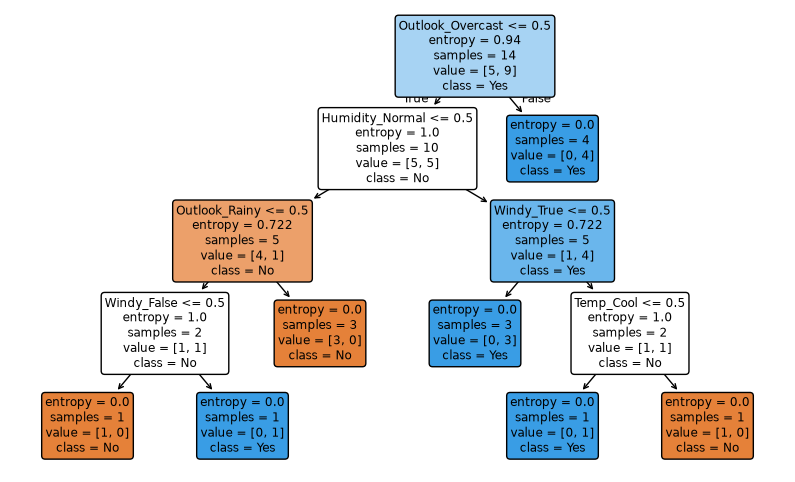

In [9]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(10, 6))
plot_tree(model, feature_names=list(X.columns), class_names=list(model.classes_),
          filled=True, rounded=True, ax=ax)   # colour shows the majority class of each node
plt.show()

## Try it

Slide 27 warns that information gain favours attributes such as a day number, which split the data into 14 single-day branches. Add a `Day` column (D1, …, D14) and compare its information gain and gain ratio with Outlook's. **What do you notice?**

In [10]:
with_day = df.assign(Day=[f"D{i}" for i in range(1, 15)])

for a in ["Day", "Outlook"]:
    g = information_gain(with_day, a)
    s = split_info(with_day, a)
    print(f"{a:8s} gain = {g:.3f}   split info = {s:.3f}   gain ratio = {g / s:.3f}")

Day      gain = 0.940   split info = 3.807   gain ratio = 0.247
Outlook  gain = 0.247   split info = 1.577   gain ratio = 0.156


<details>
<summary>Answer</summary>

`Day` has the largest possible gain (0.940, all of the target's entropy), because every branch holds a single day and is pure. The gain ratio divides this by a large split info (log₂ 14 = 3.807), which cuts it to 0.247, but that is still higher than Outlook's 0.156 (0.157 on slide 30). So the gain ratio reduces the bias towards many-valued attributes without removing it, which is why identifier columns such as `Day` should be dropped before building a tree. A tree that splits on `Day` cannot classify a new day (slide 27: "D15?").

</details>